In [1]:
pip install -U mplhep

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import coffea.util
import matplotlib.pyplot as plt
import yaml
import awkward as ak

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.studyingDYjetsWithData import tools
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()
%matplotlib inline

In [3]:
ratio = 6.616 /59.83

In [4]:
data = functions.get_data_files()
data = [x for x in data if "C" in x]
channel_name  = "cr_1LJ_Zmumu_cosmicVeto"
TT = functions.get_bg_file_names("TTJets")
DY = functions.get_bg_file_names("DYJetsToLL")
QCD = functions.get_bg_file_names("QCD")
DB = functions.get_bg_file_names("Diboson")
folder_name = f"OutputFiles/{channel_name}"
sum_data_all= utilities.sum_hist(data, folder_name)
summed_QCD = utilities.sum_hist(QCD, folder_name)
summed_TT  = utilities.sum_hist(TT,  folder_name)
summed_DY  = utilities.sum_hist(DY, folder_name)
summed_DB  = utilities.sum_hist(DB,  folder_name)

In [5]:
list(sum_data_all.keys())

['muon_muon_invmass',
 'muon_muon_invmass_highRange',
 'muon_n',
 'electron_n',
 'dsaMuon_n',
 'photon_n',
 'mu_lj_mass',
 'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
 'mu_mu_dphi',
 'mu_mu_inv_mass',
 'jet_n',
 'jet_pt',
 'jet_eta_phi',
 'muon_pt',
 'muon_eta_phi',
 'muN_muLj_muN_diff',
 'mu_lj_muonN',
 'mu_lj_pfMu_n',
 'mu_lj_dsaMu_n',
 'mu_lj_pt',
 'mu_lj_muon_pt',
 'mu_lj_pfMuon_pt',
 'mu_lj_dsaMuon_pt',
 'jet0Pt_muLj0_pt',
 'jet0_muLj0_dPhi',
 'mu0_mu1_dphi',
 'mu0_mu1_dR']

jet_n
electron_n


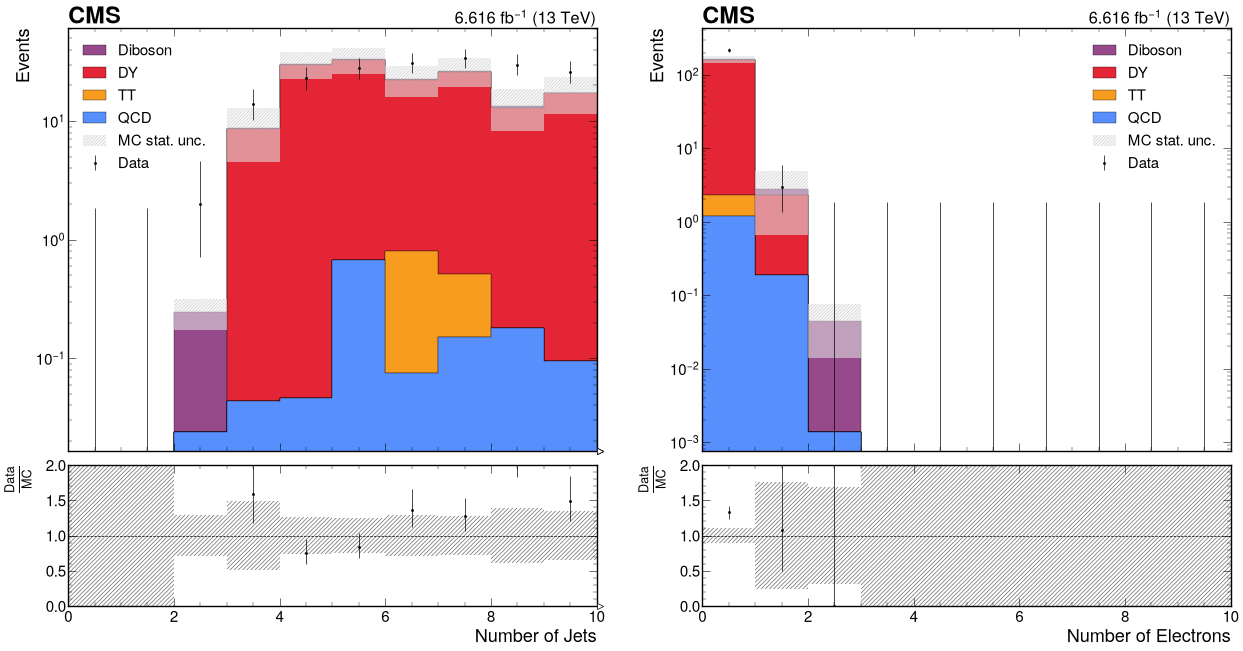

In [30]:
histogram_list  = [ 
'jet_n','electron_n'
]
functions.plot_DataMC(histogram_list,channel_name, summed_QCD, summed_TT, summed_DY, summed_DB, sum_data_all, ratio, binning=1j, file_name=f"{channel_name}_lj_pt", lumi=6.616)


jet_pt


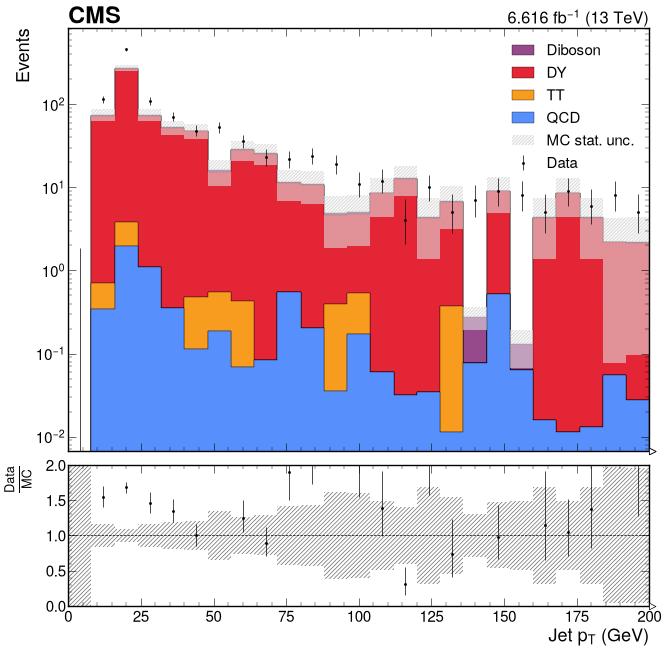

In [28]:
histogram_list  = [ 

 'jet_pt',
]
functions.plot_DataMC(histogram_list,channel_name, summed_QCD, summed_TT, summed_DY, summed_DB, sum_data_all, ratio, binning=4j, file_name=f"{channel_name}_lj_pt", lumi=6.616)


muon_n
dsaMuon_n
mu_lj_muonN
mu_lj_pfMu_n
mu_lj_dsaMu_n


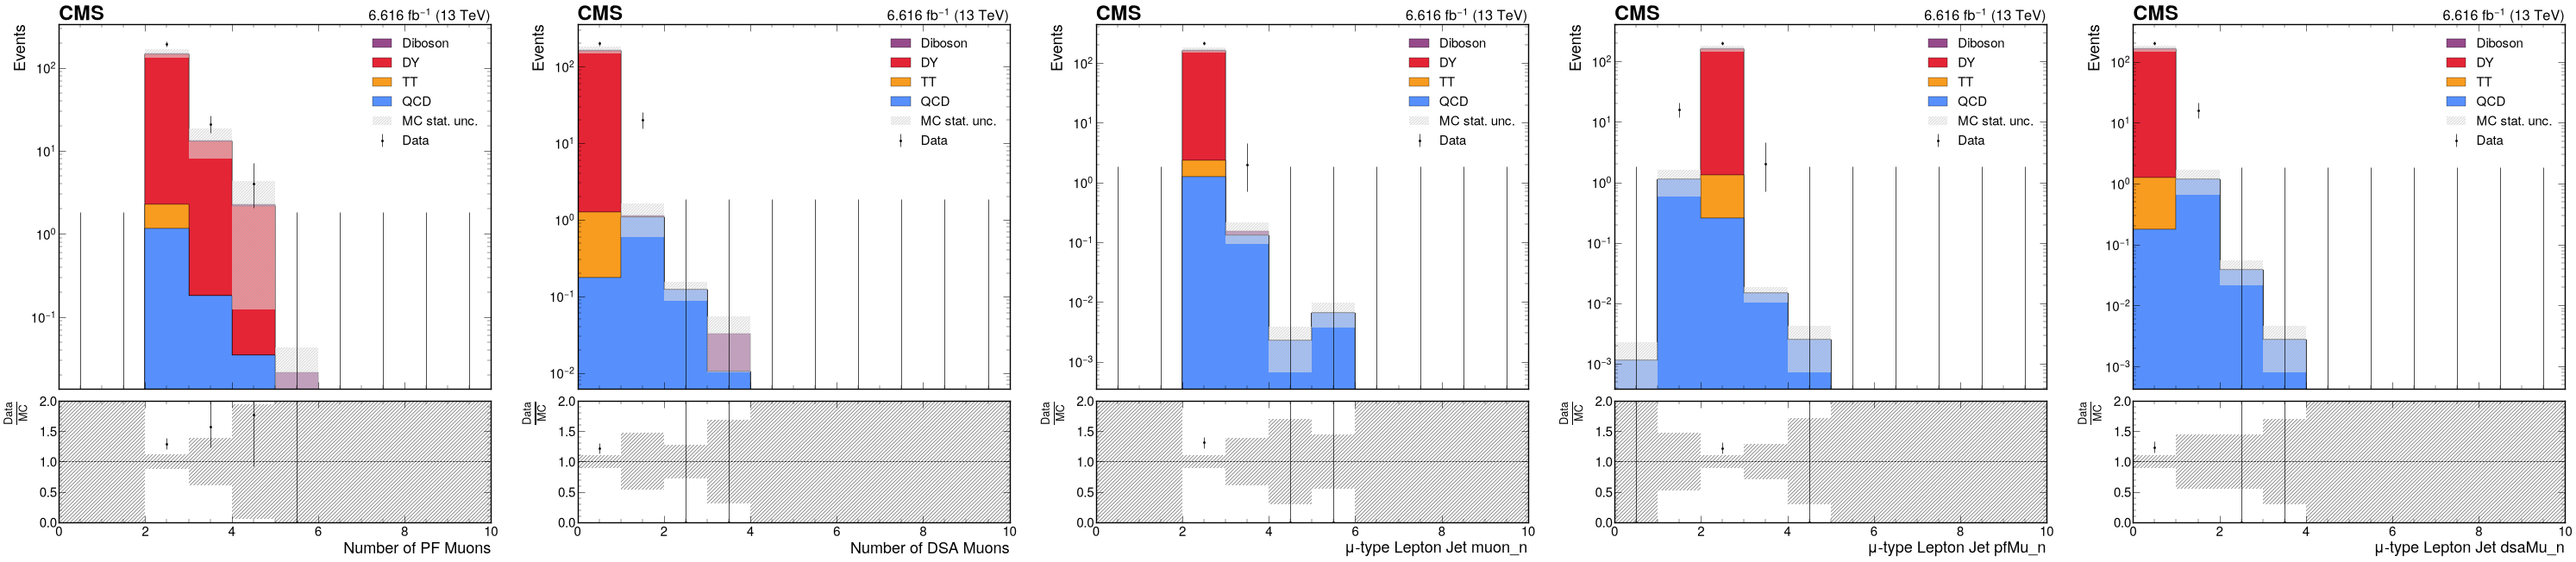

In [6]:
histogram_list  = [ 
'muon_n','dsaMuon_n','mu_lj_muonN',
 'mu_lj_pfMu_n',
 'mu_lj_dsaMu_n',
]
functions.plot_DataMC(histogram_list,channel_name, summed_QCD, summed_TT, summed_DY, summed_DB, sum_data_all, ratio, binning=1j, file_name=f"{channel_name}_lj_pt", lumi=6.616)


muon_muon_invmass
mu0_mu1_dphi
jet0_muLj0_dPhi
mu0_mu1_dR


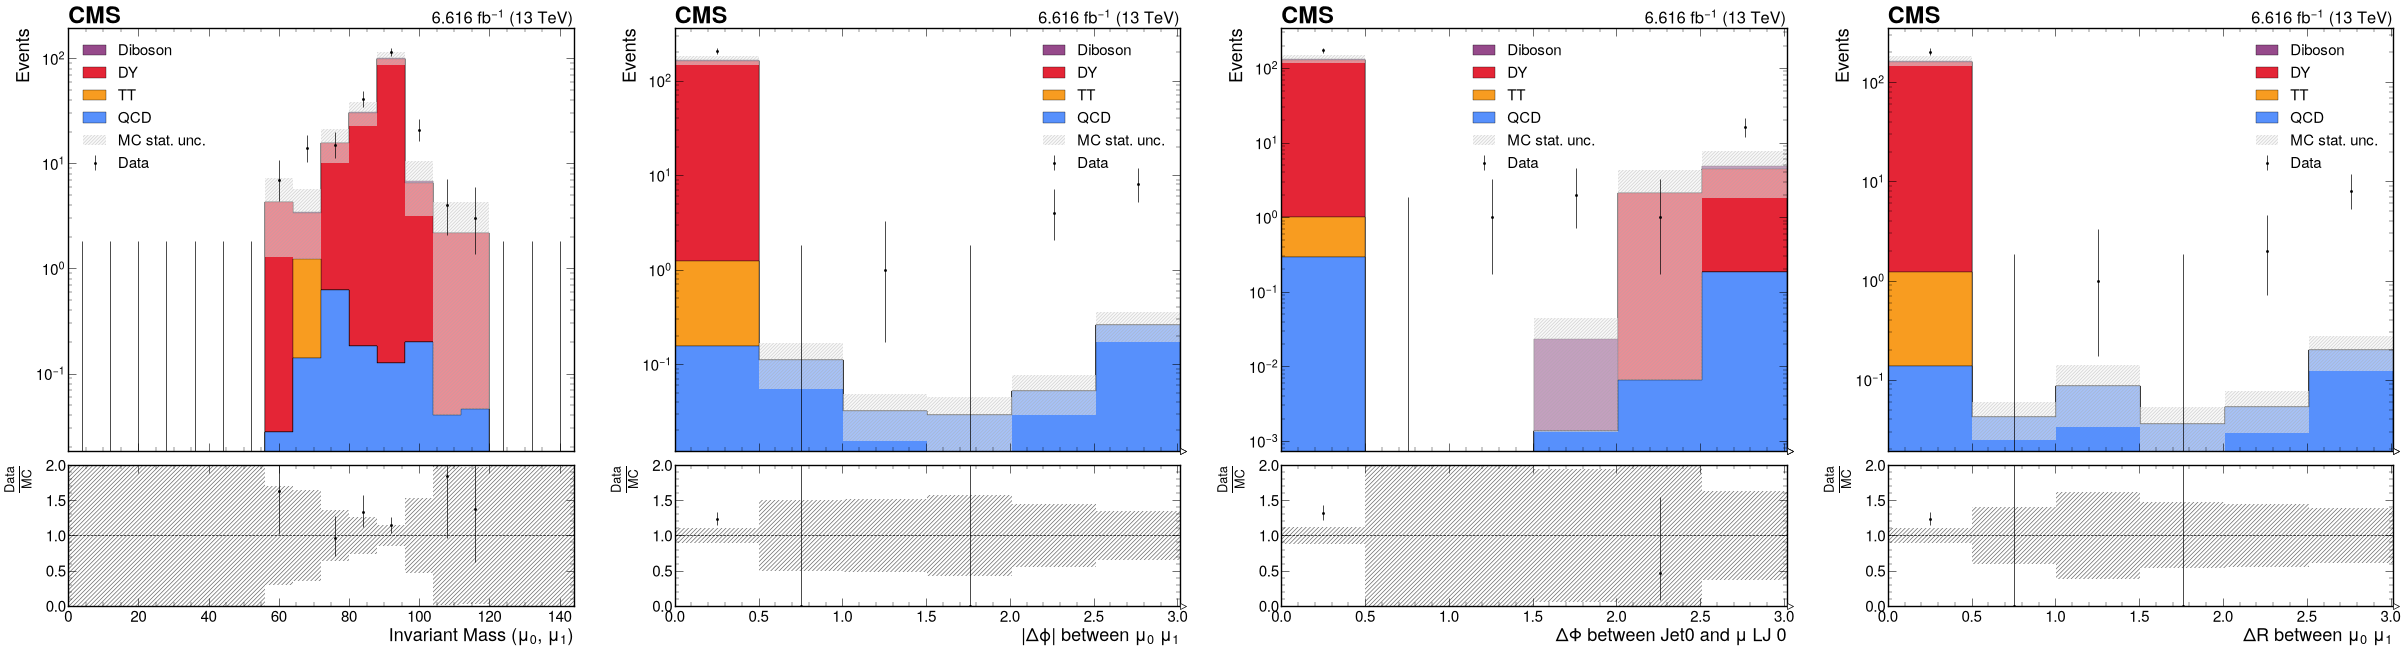

In [25]:
histogram_list = ['muon_muon_invmass', 'mu0_mu1_dphi','jet0_muLj0_dPhi','mu0_mu1_dR'

]

functions.plot_DataMC(histogram_list,channel_name, summed_QCD, summed_TT, summed_DY, summed_DB, sum_data_all, ratio, binning=8j, file_name=f"{channel_name}_inv_mass_muon", lumi=6.616)

muN_muLj_muN_diff


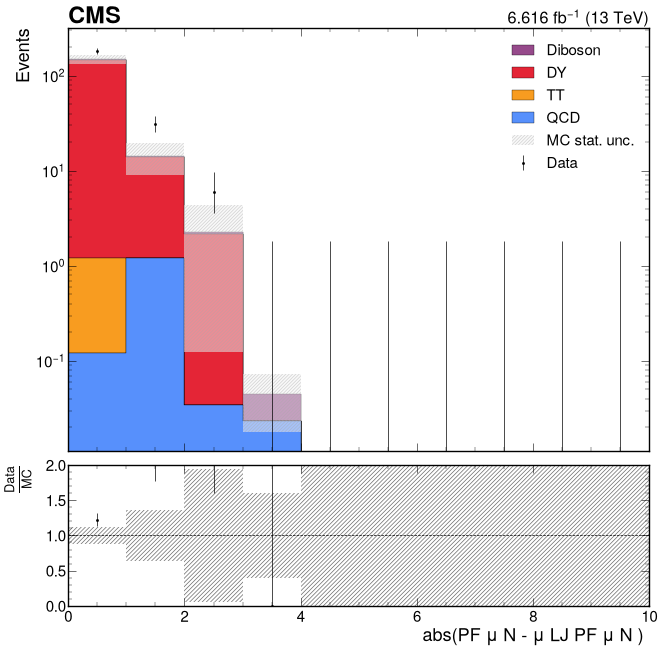

In [20]:
histogram_list = ['muN_muLj_muN_diff',

]

functions.plot_DataMC(histogram_list,channel_name, summed_QCD, summed_TT, summed_DY, summed_DB, sum_data_all, ratio, binning=1j, file_name=f"{channel_name}_inv_mass_muon", lumi=6.616)

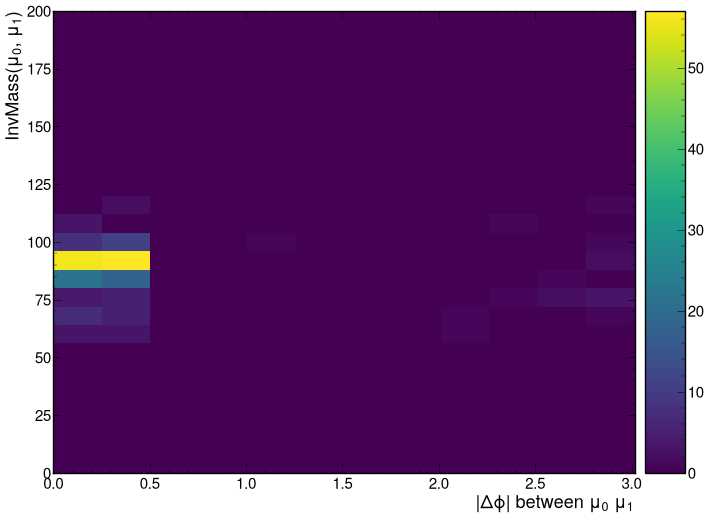

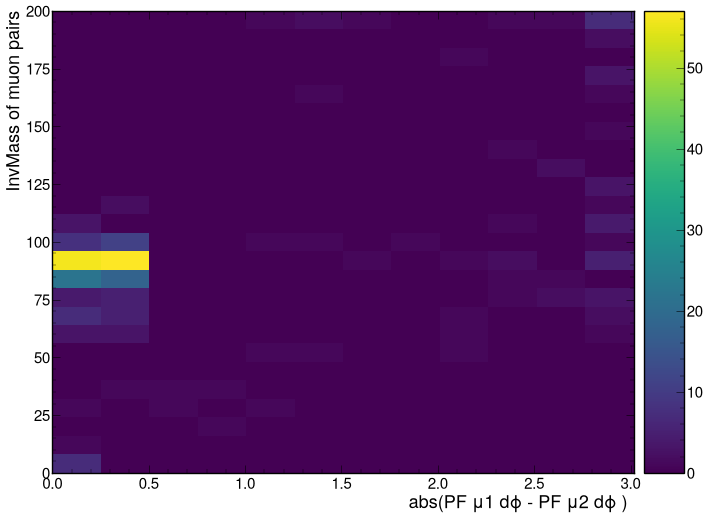

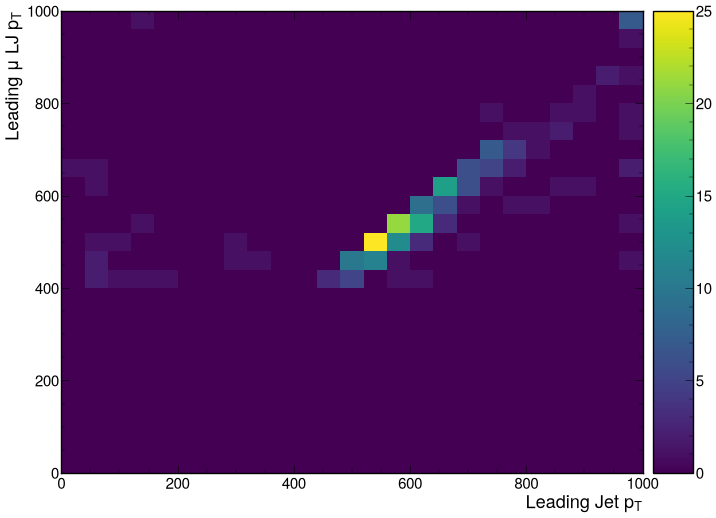

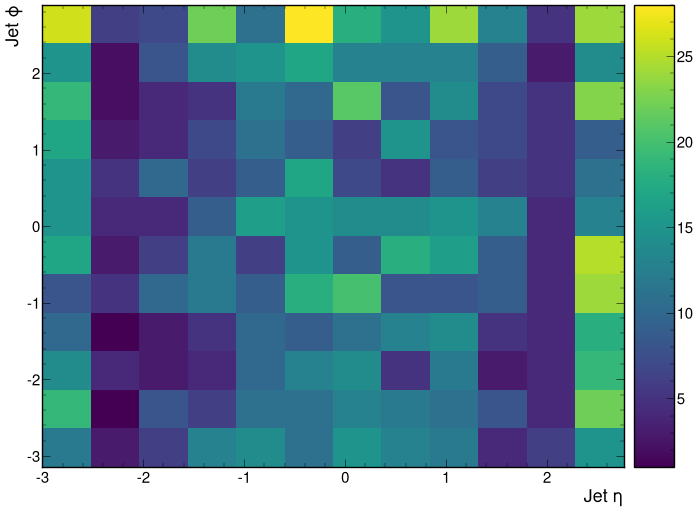

In [24]:
histogram_list = [
     'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
    'jet0Pt_muLj0_pt',
    'jet_eta_phi',
]

for j, histogram_name in enumerate(histogram_list):
    try:
        histogram = sum_data_all[histogram_name][channel_name,:]
    except:
        try:
            histogram = sum_data_all[histogram_name][channel_name,::4j,::4j]
        except:  
            continue
    plt.figure(figsize=(15, 12))
    utilities.plot(histogram, skip_label = True)
    plt.show()
    plt.close()


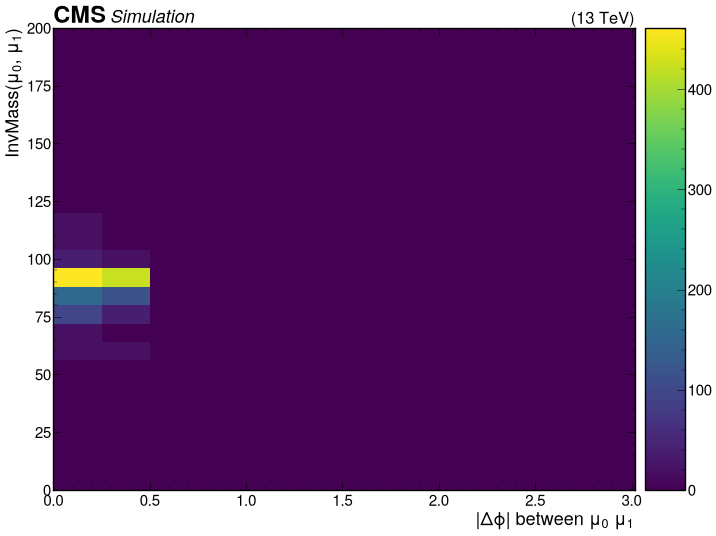

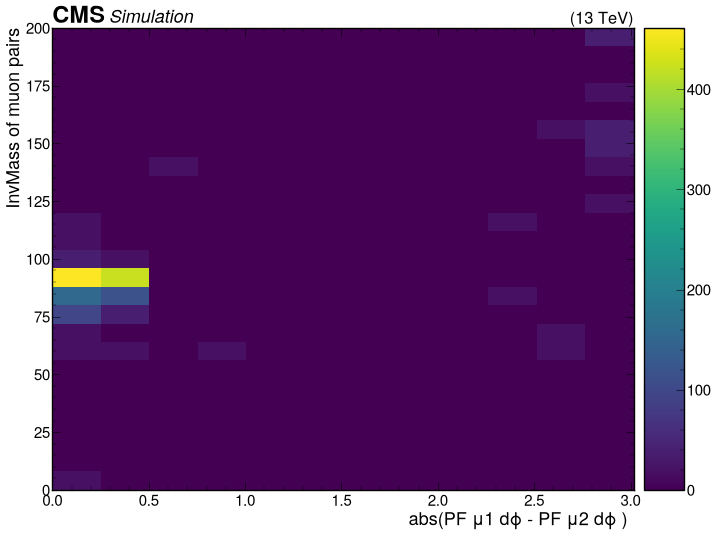

In [29]:
histogram_list = [
     'mu0_mu1_dphi_invMass',
 'mu_mu_dphi_invMass',
]

for j, histogram_name in enumerate(histogram_list):
    try:
        histogram = summed_DY[histogram_name][channel_name,:]
    except:
        try:
            histogram = summed_DY[histogram_name][channel_name,::4j,::4j]
        except:  
            continue
    plt.figure(figsize=(15, 12))
    utilities.plot(histogram)
    plt.show()
    plt.close()